# Recumbent fold — figures

Publication figures for the recumbent-fold example, made **only from saved
results** in `results/<DATASET>/`. Nothing is fitted here and `curlew`,
`torch` and `surfepy` are not needed — just numpy and matplotlib (plus
`cmasher` for the paleo-grid colours, if installed).

| file | written by | contents |
|---|---|---|
| `inputs.npz` | `01b_recumbent_fold_fit` | contacts, normals, evaluation grid |
| `nf.npz`, `ldi.npz` | `01b_recumbent_fold_fit` | scalar, lithology, critical points (LDI: deformed paleo grid) |
| `surfe.npz` | `01c_recumbent_fold_surfe` | Surfe scalar, lithology, critical points on the same grid |
| `ensemble_nf.npz`, `ensemble_ldi.npz`, `ensemble_members.csv` | `01d_recumbent_fold_ensemble` | per-member scores against the truth, share of members matching it |
| `nf_field.pt`, `ldi_field.pt` | `01b_recumbent_fold_fit` | fitted field parameters (not read here) |

Figures are written to `figures/`.

In [6]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
figstyle.apply()

try:
    import cmasher as cmr
    PALEO_CMAP = cmr.guppy
except ImportError:
    PALEO_CMAP = plt.get_cmap("viridis")

DATASET = "synthetic"
RES_DIR = Path("./results") / DATASET
SUFFIX = f"_{DATASET}"
FIG_DIR = Path("./figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


## Load

Contacts and normals are in the figures' own coordinates (shifted to the data
centroid, as fitted).

In [7]:
inp = np.load(RES_DIR / "inputs.npz")
horizon_names = [str(n) for n in inp["horizon_names"]]
horizons = [inp[f"horizon_{i}"] for i in range(len(horizon_names))]
gp, gv = inp["gp"], inp["gv"]
x, z = inp["x"], inp["z"]
xlim, zlim = (float(x[0]), float(x[-1])), (float(z[0]), float(z[-1]))
extent = (*xlim, *zlim)
horizon_colors = {
    name: figstyle.HORIZON_PALETTE[i % len(figstyle.HORIZON_PALETTE)]
    for i, name in enumerate(horizon_names)
}

# True contacts in the same shifted frame, synthetic data only. rock2 is H0.
truth_contacts = None
if DATASET == "synthetic":
    truth = np.load(Path("./data/synthetic/truth.npz"))
    truth_contacts = [truth[f"contact_{name}"] - inp["origin"] for name in ("rock2", "rock1")]

ldi, surfe = (np.load(RES_DIR / f"{k}.npz") for k in ("ldi", "surfe"))

crit = {k: diagnostics.unpack_critical(d) for k, d in (("SURFE", surfe), ("LDI", ldi))}
for k, c in crit.items():
    print(f"{k}: maxima={c.counts['maximum']}, minima={c.counts['minimum']}, saddles={c.counts['saddle']}")

litho_ids = np.unique(np.concatenate([d["lithology"].ravel() for d in (surfe, ldi)]))
cmap_litho, norm_litho = figstyle.litho_cmap(litho_ids)
ramp = figstyle.ramp()


def _field(ax, field, cmap, **kw):
    return ax.imshow(
        np.asarray(field).T, origin="lower", extent=extent, cmap=cmap,
        interpolation="nearest", aspect="equal", rasterized=True, **kw,
    )

# Isovalue of each contact set, so the intermediate contours skip them
iso = {"SURFE": surfe["isovalues"], "LDI": ldi["isovalues"]}

SURFE: maxima=1, minima=1, saddles=2
LDI: maxima=0, minima=0, saddles=0


## Figure 1 — SURFE vs LDI

Top row, the radial-basis-function interpolant (SURFE): the data, with the true
contacts drawn behind the picks, scalar ψ with its
interior extrema, and lithology. Bottom row, the restore (LDI): the deformed
paleo grid, ψ, and lithology. Thin grey lines in the ψ panels are intermediate
isocontours at evenly spaced levels; they show whether the isosurfaces between
and beyond the contacts close on themselves (SURFE) or continue through the
fold (LDI).

In [8]:
# Deformed paleo grid (stored as pushed-forward polylines; horizontals then verticals)
present_grid = ldi["present_grid"].astype(float)
z_lines, s_z, n_along = ldi["z_lines"], ldi["s_z"], int(ldi["n_along"])
n_h = len(z_lines)
n_v = len(present_grid) // n_along - n_h
h_pts = present_grid[: n_h * n_along].reshape(n_h, n_along, 2)
v_pts = present_grid[n_h * n_along :].reshape(n_v, n_along, 2)

norm_z = Normalize(vmin=float(zlim[0]) + 100.0, vmax=float(zlim[1]) - 100.0)
h_colors = PALEO_CMAP(norm_z(z_lines))
v_colors = PALEO_CMAP(norm_z(0.5 * (s_z[:-1] + s_z[1:])))
sm_z = plt.cm.ScalarMappable(norm=norm_z, cmap=PALEO_CMAP)
sm_z.set_array([])


def draw_grid(ax, lw):
    for line, col in zip(h_pts, h_colors):
        ax.plot(line[:, 0], line[:, 1], color=col, lw=lw, solid_capstyle="round", zorder=2)
    for line in v_pts:
        segs = np.stack([line[:-1], line[1:]], axis=1)
        ax.add_collection(LineCollection(
            segs, colors=v_colors, linewidths=lw, capstyle="round", zorder=2,
        ))

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


wrote figures/fig01_recumbent_fold_synthetic.pdf, figures/fig01_recumbent_fold_synthetic.png


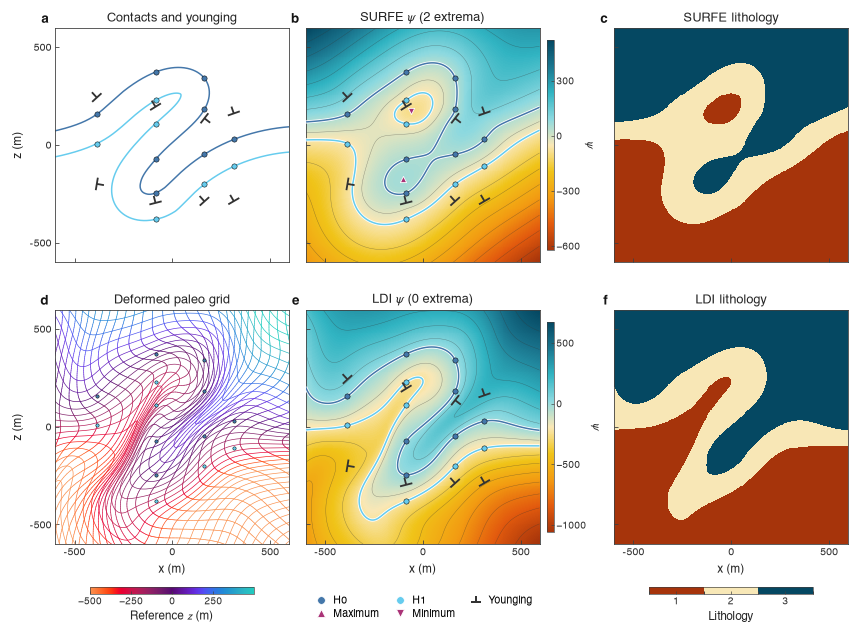

In [9]:
fig, grid = figstyle.comparison_grid(2, 3, xlim=xlim, zlim=zlim)
sf_s, sf_r = surfe["scalar"], ldi["scalar"]
constraint_kw = dict(colors=horizon_colors, scatter_s=10, quiver_scale=0.013)

# Top row — Data and SURFE
ax = grid[0]
if truth_contacts is not None:
    for name, pts in zip(horizon_names, truth_contacts):
        ax.plot(pts[:, 0], pts[:, 1], color=horizon_colors[name], lw=0.9,
                solid_capstyle="round", zorder=1)
figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv, **constraint_kw)
figstyle.format_section_ax(ax, xlabel=False, title="Contacts and younging")
figstyle.set_view(ax, xlim, zlim)
figstyle.hide_cbar(grid.cbar_axes[0])

ax = grid[1]
im_sfi = _field(ax, sf_s, ramp)
figstyle.draw_intermediate_contours(ax, x, z, sf_s, skip_levels=iso["SURFE"])
figstyle.draw_contact_contours(ax, x, z, sf_s, horizons, horizon_names, colors=horizon_colors, levels=iso["SURFE"])
figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv, **constraint_kw)
figstyle.format_section_ax(ax, xlabel=False, ylabel=False, title=diagnostics.extrema_title("SURFE", crit["SURFE"]))
figstyle.set_view(ax, xlim, zlim)
figstyle.add_cbar(grid.cbar_axes[1], im_sfi, r"$\psi$", scientific=False)
diagnostics.overlay_critical_points(ax, crit["SURFE"], size=14)

ax = grid[2]
im_litho = _field(ax, surfe["lithology"], cmap_litho, norm=norm_litho)
figstyle.format_section_ax(ax, xlabel=False, ylabel=False, title="SURFE lithology")
figstyle.set_view(ax, xlim, zlim)
figstyle.hide_cbar(grid.cbar_axes[2])

# Bottom row — Geometric restoration
ax = grid[3]
draw_grid(ax, lw=0.4)
figstyle.overlay_constraints(
    ax, horizons, horizon_names, gp, gv,
    colors=horizon_colors, scatter_s=4, show_quiver=False,
)
figstyle.format_section_ax(ax, title="Deformed paleo grid")
figstyle.set_view(ax, xlim, zlim)
figstyle.hide_cbar(grid.cbar_axes[3])

ax = grid[4]
im_sfr = _field(ax, sf_r, ramp)
figstyle.draw_intermediate_contours(ax, x, z, sf_r, skip_levels=iso["LDI"])
figstyle.draw_contact_contours(ax, x, z, sf_r, horizons, horizon_names, colors=horizon_colors, levels=iso["LDI"])
figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv, **constraint_kw)
figstyle.format_section_ax(ax, ylabel=False, title=diagnostics.extrema_title("LDI", crit["LDI"]))
figstyle.set_view(ax, xlim, zlim)
figstyle.add_cbar(grid.cbar_axes[4], im_sfr, r"$\psi$", scientific=False)
diagnostics.overlay_critical_points(ax, crit["LDI"], size=14)

ax = grid[5]
_field(ax, ldi["lithology"], cmap_litho, norm=norm_litho)
figstyle.format_section_ax(ax, ylabel=False, title="LDI lithology")
figstyle.set_view(ax, xlim, zlim)
figstyle.hide_cbar(grid.cbar_axes[5])

for ax, letter in zip(grid.axes, "abcdef"):
    figstyle.panel_label(ax, letter)

# Row 1: horizons and younging; row 2: extrema. Matplotlib fills legends
# column by column, so interleave the two rows and pad the second.
legend_rows = [
    figstyle.constraint_handles(horizon_colors, horizon_names),
    diagnostics.extrema_handles(crit["SURFE"], crit["LDI"]),
]
legend_ncol = len(legend_rows[0])
legend_rows[1] += [Line2D([], [], ls="", label="")] * (legend_ncol - len(legend_rows[1]))
legend_handles = [row[j] for j in range(legend_ncol) for row in legend_rows]
# Bottom band, tops level: paleo-z colour bar under d, legend under e, and one
# lithology colour bar under f (c and f share the classes).
figstyle.bottom_cbar(grid.axes[3], sm_z, r"Reference $z$ (m)")
figstyle.bottom_cbar(grid.axes[5], im_litho, "Lithology", ticks=litho_ids)
figstyle.bottom_legend(grid.axes[4], legend_handles, ncol=legend_ncol)

written = figstyle.save(fig, FIG_DIR / f"fig01_recumbent_fold{SUFFIX}")
print("wrote", ", ".join(str(p) for p in written))
plt.show()

## Figure 2 — the Fourier-seed ensembles

The NF and LDI ensembles of `01d_recumbent_fold_ensemble` (`N` Fourier seeds each, same data,
basis and training as the single fits), with the single Surfe fit of `01c` alongside.
Every fit is scored against the truth where the drillholes can decide the geometry
(`recumbent_inputs.score_against_truth`; run 01c and 01d first):

- **a, b** for each method, the share of members that put each grid cell in its true unit,
  with the drillholes, the scoring window, the true contacts and the data;
- **c** per horizon, the median distance between the fitted and the true contact within
  the scoring window (the outer holes widened by half the mean hole spacing), both ways round;
- **d** per unit, intersection over union with the true unit within that window.

Topology is scored by the interior extrema alone (`diagnostics.find_critical_points`).

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


wrote figures/fig02_recumbent_fold_ensemble_synthetic.pdf, figures/fig02_recumbent_fold_ensemble_synthetic.png


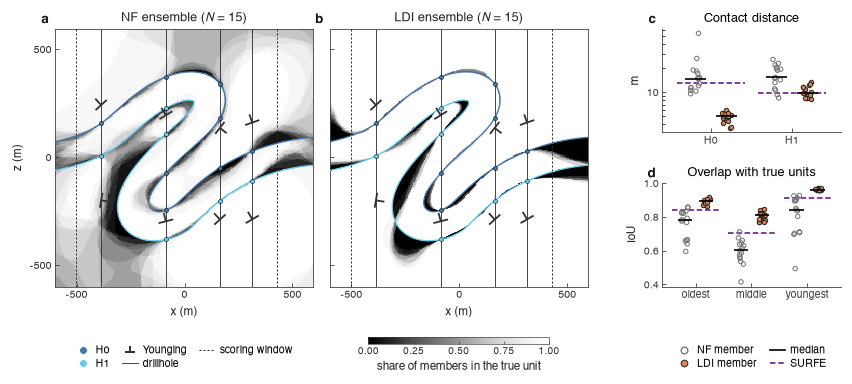

In [11]:
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, NullFormatter
import recumbent_inputs

members = pd.read_csv(RES_DIR / "ensemble_members.csv")
ens = {k: np.load(RES_DIR / f"ensemble_{k.lower()}.npz") for k in ("NF", "LDI")}
n_members = int(ens["LDI"]["n_members"])
reference = recumbent_inputs.truth_reference(inp["origin"], Path("./data"))
window = reference["window"]

METHOD_STYLE = {"NF": dict(color="0.45", filled=False), "LDI": dict(color="#DD8452", filled=True)}
SURFE_COLOR = "#7B3294"
UNIT_NAMES = ["oldest", "middle", "youngest"]

# Layout in inches: one row, the two maps (a, b) and a narrow column with the contact
# distances (c) above the overlaps (d).
W = figstyle.PRINT_WIDTH
left, right, top, bottom = 0.48, 0.06, 0.26, 0.92
map_size, map_gap, strip_gap, strip_vgap = 2.15, 0.14, 0.62, 0.42
strip_w = W - left - 2 * map_size - map_gap - strip_gap - right
strip_h = (map_size - strip_vgap) / 2
H = top + map_size + bottom
fig = figstyle.print_figure(height=H)
place = lambda x0, t, w, h: fig.add_axes((x0 / W, (H - t - h) / H, w / W, h / H))
maps = [place(left + i * (map_size + map_gap), top, map_size, map_size) for i in range(2)]
x_strip = left + 2 * map_size + map_gap + strip_gap
strips = [place(x_strip, top + i * (strip_h + strip_vgap), strip_w, strip_h) for i in range(2)]


def strip(ax, columns, labels, log=False, surfe_values=None):
    # one group per column; NF and LDI side by side, member dots, median bar, Surfe's single fit as a line
    rng = np.random.default_rng(0)
    for g, col in enumerate(columns):
        for j, (k, st) in enumerate(METHOD_STYLE.items()):
            v = members.loc[members["method"] == k, col].to_numpy(float)
            xs = g + (j - 0.5) * 0.38 + rng.uniform(-0.06, 0.06, len(v))
            ax.scatter(xs, v, s=7, linewidths=0.6, zorder=3,
                       facecolors=st["color"] if st["filled"] else "none", edgecolors=st["color"] if not st["filled"] else "0.15")
            ax.hlines(np.median(v), g + (j - 0.5) * 0.38 - 0.13, g + (j - 0.5) * 0.38 + 0.13, color="k", lw=1.0, zorder=4)
        if surfe_values is not None:
            ax.hlines(surfe_values[g], g - 0.42, g + 0.42, color=SURFE_COLOR, lw=1.1, ls=(0, (3, 1.5)), zorder=2)
    ax.set_xticks(range(len(columns)), labels)
    ax.set_xlim(-0.6, len(columns) - 0.4)
    if log:
        ax.set_yscale("log")
        # Plain-number tick labels: the log axis' default mathtext labels (10^k) fail to render in this
        # matplotlib build (FT_Load_Glyph, division by zero).
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.yaxis.set_minor_formatter(NullFormatter())
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


strip(strips[0], [f"contact_distance_{n}" for n in horizon_names], horizon_names, log=True,
      surfe_values=surfe["contact_distance"])
strips[0].set_title("Contact distance")
strips[0].set_ylabel("m")
strip(strips[1], [f"iou_unit_{u}" for u in (1, 2, 3)], UNIT_NAMES, surfe_values=surfe["iou"])
strips[1].set_title("Overlap with true units")
strips[1].set_ylabel("IoU")
fig.align_ylabels(strips)

for ax, k in zip(maps, ("NF", "LDI")):
    m = ax.pcolormesh(x, z, ens[k]["match_fraction"].T, cmap="Greys_r", vmin=0.0, vmax=1.0, shading="auto",
                      rasterized=True, zorder=0)
    for xh in reference["holes"]:
        ax.axvline(xh, color="0.15", lw=0.5, zorder=2)
    for xw in window:
        ax.axvline(xw, color="0.15", lw=0.6, ls=(0, (2, 2)), zorder=2)
    for name, pts in zip(horizon_names, truth_contacts):
        ax.plot(pts[:, 0], pts[:, 1], color=horizon_colors[name], lw=0.8, zorder=3)
    figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv, colors=horizon_colors, scatter_s=6,
                                 quiver_scale=0.012)
    figstyle.format_section_ax(ax, ylabel=k == "NF", title=f"{k} ensemble ($N$ = {n_members})")
    figstyle.set_view(ax, xlim, zlim)
    if k == "LDI":
        ax.tick_params(labelleft=False)

for ax, letter in zip(maps + strips, "abcd"):
    figstyle.panel_label(ax, letter)

method_handles = [Line2D([], [], ls="", marker="o", ms=4, mfc="none", mec=METHOD_STYLE["NF"]["color"], mew=0.8, label="NF member"),
                  Line2D([], [], ls="", marker="o", ms=4, mfc=METHOD_STYLE["LDI"]["color"], mec="0.15", mew=0.6, label="LDI member"),
                  Line2D([], [], color="k", lw=1.0, label="median"),
                  Line2D([], [], color=SURFE_COLOR, lw=1.1, ls=(0, (3, 1.5)), label="SURFE")]
figstyle.bottom_legend(strips[1], method_handles, ncol=2, drop=0.42)
map_handles = (figstyle.constraint_handles(horizon_colors, horizon_names)
               + [Line2D([], [], color="0.15", lw=0.5, label="drillhole"),
                  Line2D([], [], color="0.15", lw=0.6, ls=(0, (2, 2)), label="scoring window")])
figstyle.bottom_legend(maps[0], map_handles, ncol=3, drop=0.42)
figstyle.bottom_cbar(maps[1], m, "share of members in the true unit", drop=0.42)

written = figstyle.save(fig, FIG_DIR / f"fig02_recumbent_fold_ensemble{SUFFIX}")
print("wrote", ", ".join(str(p) for p in written))
plt.show()